# Lesson 6 · Machine-Learning Forecasting: Lag Features, Random Forest, Gradient Boosting & XGBoost
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 15** &nbsp;|&nbsp; ⏱ ≈ 120 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Reframe forecasting as **supervised learning** with lag, rolling and calendar features
> - Choose a **stationary, scale-free target** (returns) and understand why trees *cannot extrapolate*
> - Fit **Linear/Ridge, Random Forest, Gradient Boosting and XGBoost** forecasters
> - Contrast **direct vs recursive** multi-step strategies
> - Tune with **time-aware cross-validation** and evaluate with **walk-forward** validation
> - Interpret models with **permutation importance**

**Prerequisites:** Lessons 2 (features, leakage) and 3 (walk-forward), plus ML basics from earlier phases.

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## 1 · From a series to a table

The statistical models of Lessons 4–5 are *built for* time series. Machine-learning models are built for **tables**: rows of features `X` and a target `y`.
Any series can be turned into such a table (Lesson 2): each row is a *forecast origin*; the features describe what we know *then*; the target is the future value.

| | Statistical (ARIMA, ETS) | ML on lag features |
|---|---|---|
| Handles many **exogenous drivers** | awkward (linear only) | natural |
| **Non-linear** effects / interactions | no | yes (trees, boosting) |
| **Multiple related series** in one model | no | yes (add a commodity feature) |
| Needs lots of data | no | more |
| Gives intervals out of the box | yes | no (needs quantile models / conformal) |
| Understands time structure *natively* | yes | only through the features **you** craft |
| Extrapolates trends | yes (differencing, drift) | **trees: no!** |

> 💡 The last row hides the key lesson of this chapter. Let's see it with our own eyes.

## 2 · The extrapolation trap: *why a forest can't follow a trend*

A Random Forest predicts by **averaging training targets** stored in its leaves, so it can never output a value beyond the training maximum. Maize prices keep rising across our history…

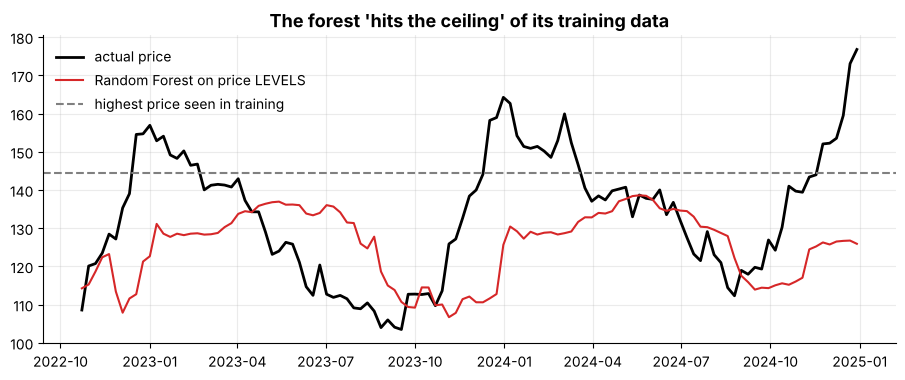

MAE: 15.46


In [2]:
from sklearn.ensemble import RandomForestRegressor
mz = load_weekly("maize")
h = 8

# (A) Naive ML recipe: features = lagged PRICES, target = PRICE LEVEL
XA, yA = make_features(mz, lags=(8, 9, 10, 12, 52), windows=(4, 12), h=h)
dA = XA.join(yA.rename("y")).dropna(); k = int(len(dA) * 0.8)                 # chronological 80/20
rfA = RandomForestRegressor(200, random_state=0).fit(dA.drop(columns="y").iloc[:k], dA["y"].iloc[:k])
predA = pd.Series(rfA.predict(dA.drop(columns="y").iloc[k:]), index=dA.index[k:])

fig, ax = plt.subplots()
ax.plot(mz["price"].loc[dA.index[k:]], color="black", lw=2, label="actual price")
ax.plot(predA, color="tab:red", label="Random Forest on price LEVELS")
ax.axhline(dA["y"].iloc[:k].max(), color="gray", ls="--", label="highest price seen in training")
ax.legend(); ax.set_title("The forest 'hits the ceiling' of its training data"); plt.show()
print("MAE:", round(mae(mz["price"].loc[predA.index], predA), 2))

### The fix: predict **returns**, not levels

Instead of "what will the price be?", ask **"by what percentage will the price change over the next *h* weeks?"**

$$y_t = \log p_t - \log p_{t-h}\qquad\Longrightarrow\qquad \hat p_t = p_{t-h}\cdot e^{\hat y_t}$$

- The return is **stationary** and **scale-free** (a +5 % move means the same at 50 or 150).
- The *trend* lives in the known base price $p_{t-h}$, not in the model.
- Features become scale-free too: **past returns** over several windows, distance from a moving average, recent volatility: plus seasonal Fourier terms and *lagged* drivers.

This is exactly what `make_ml_table` does. Study the features it builds:

In [3]:
X8, y8 = make_ml_table(mz, h=8)
print("Target :", y8.name, "= log(p_t) - log(p_{t-8})")
print("Features:", list(X8.columns))
X8.join(y8).dropna().head(3).round(3)

Target : ret_target_h8 = log(p_t) - log(p_{t-8})
Features: ['ret_1w', 'ret_2w', 'ret_3w', 'ret_4w', 'ret_8w', 'ret_13w', 'ret_26w', 'ret_52w', 'dev_ma12', 'vol_13', 'rain6_l8', 'fuel_l8', 'fest', 'sin1', 'cos1', 'sin2', 'cos2', 'sin3', 'cos3']


,ret_1w,ret_2w,ret_3w,ret_4w,ret_8w,ret_13w,ret_26w,ret_52w,dev_ma12,vol_13,rain6_l8,fuel_l8,fest,sin1,cos1,sin2,cos2,sin3,cos3,ret_target_h8
date,,,,,,,,,,,,,,,,,,,,
2014-03-02,-0.022,-0.045,-0.039,0.035,0.110,0.261,0.277,0.057,0.067,0.029,0.521,-0.127,0,0.867,0.498,0.864,-0.504,-0.006,-1.000,0.063
2014-03-09,-0.033,-0.056,-0.078,-0.072,0.044,0.223,0.152,0.024,0.019,0.033,0.662,-0.147,0,0.921,0.390,0.719,-0.695,-0.359,-0.933,0.064
2014-03-16,0.057,0.024,0.001,-0.021,0.123,0.238,0.234,0.082,0.059,0.034,0.613,-0.151,0,0.961,0.277,0.532,-0.847,-0.666,-0.746,-0.007


| Feature group | Examples | Intuition |
|---|---|---|
| **Momentum** | `ret_1w … ret_52w` | Are prices already trending up or down? |
| **Mean reversion** | `dev_ma12` | How far above/below its 12-week average is the price? |
| **Risk** | `vol_13` | Turbulent markets move more |
| **Seasonality** | `sin1..cos3` | Where are we in the harvest cycle? (deterministic, known in advance) |
| **Drivers (lagged ≥ 8 w)** | `rain6_l8`, `fuel_l8`, `fest` | Weather and cost pass-through |

### 🕵️ Is it leak-free? Run the future-poisoning test

In [4]:
# Poison the PRICE after a cut-off and confirm no earlier feature row changes.
# (Driver columns come from other columns; they are lagged >= 8 weeks by construction.)
leakage_check(lambda s: make_ml_table(mz.assign(price=s), h=8)[0], mz["price"])
leakage_check(lambda s: make_ml_table(mz.assign(price=s), h=1)[0], mz["price"])

✅ No leakage detected: past rows never changed when the future was poisoned.
✅ No leakage detected: past rows never changed when the future was poisoned.


True

## 3 · The four model families

| Model | Idea | Analogy | Strengths | Watch out |
|---|---|---|---|---|
| **Linear / Ridge** | weighted sum of features | a recipe with fixed quantities | fast, interpretable, can extrapolate | linear only; scale features; Ridge handles collinear lags |
| **Random Forest** | average of many deep trees on random subsets | a *committee of independent experts* | robust, little tuning | can't extrapolate; slower |
| **Gradient Boosting** | trees added one at a time, each fixing the previous errors | *students taking turns correcting the last student's mistakes* | often most accurate | needs tuning (depth, learning rate, #trees) |
| **XGBoost** | gradient boosting, engineered for speed + regularisation | the same, with turbo and seat-belts | fast, handles missing values, strong default | many hyper-parameters |

All four share one API: `.fit(X, y)` → `.predict(X_new)`.

### 3a · One model, one split (a first look)

In [5]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

d8 = X8.join(y8.rename("y")).dropna(); k = int(len(d8) * 0.8)
Xtr, ytr, Xte, yte = d8.drop(columns="y").iloc[:k], d8["y"].iloc[:k], d8.drop(columns="y").iloc[k:], d8["y"].iloc[k:]
base_price = mz["price"].shift(8).loc[Xte.index]                       # known 8 weeks before each target
actual = mz["price"].loc[Xte.index]

models = {
    "Ridge":             make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest":     RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0),
    "XGBoost":           XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1),
}
preds = {"naive": base_price.values}
for name, m in models.items():
    preds[name] = (base_price * np.exp(m.fit(Xtr, ytr).predict(Xte))).values
print("8-week-ahead forecasts on the final 20 % of history")
score_table(actual, preds)

8-week-ahead forecasts on the final 20 % of history


,MAE,RMSE,MAPE,sMAPE
Random Forest,7.430,9.360,5.677,5.515
Ridge,8.194,9.663,6.332,6.064
Gradient Boosting,9.179,11.515,7.171,6.801
XGBoost,9.448,11.685,7.310,6.934
naive,14.954,18.236,10.873,11.260


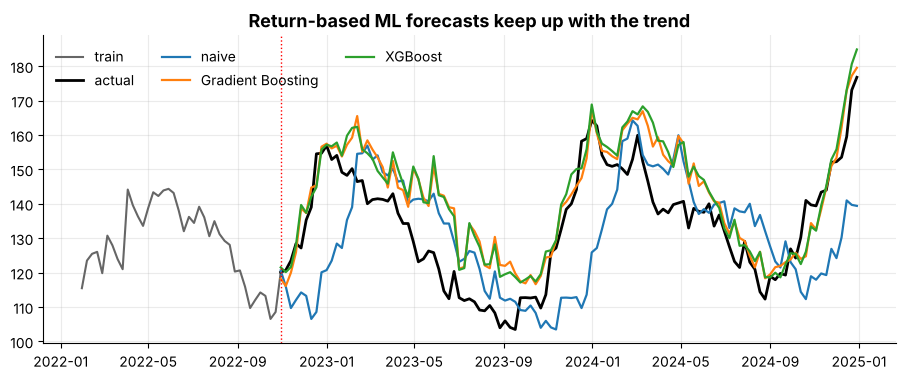

In [6]:
plot_forecasts(mz["price"].loc[:Xte.index[0]], actual, {k: v for k, v in preds.items() if k in ("naive", "Gradient Boosting", "XGBoost")},
               "Return-based ML forecasts keep up with the trend", last_train=40); plt.show()

> ⚠️ **One split is one opinion.** The table above is a *single* chronological split (and all four models already beat the naive baseline by a wide margin; compare MAE ≈ 7–9 here with ≈ 15 for the forest on raw price levels in §2). But different models may win in a different window: watch the ranking change below. To compare fairly we use **walk-forward validation**: many origins, with refitting.

## 4 · Direct multi-step forecasting & the walk-forward tournament

**Direct strategy:** train **one model per horizon**. Model *h* maps information available at the origin to the *h*-step return: this is exactly what `make_ml_table(df, h)` / `walk_forward_ml` do (features at row *t* use data ≤ *t − h*).

| Strategy | How | Pros | Cons |
|---|---|---|---|
| **Direct** | a model for each h | no error feedback; each model optimised for its horizon | more models; horizons modelled independently |
| **Recursive** | one 1-step model, applied repeatedly | single model; consistent | errors compound; needs forecasts of every feature |
| **Multi-output** | one model with *h* outputs | compact | not all libraries support it |

We evaluate at horizons 1, 4 and 8 weeks, with 19 forecast origins (`initial=470`, `step=8`, refit at every origin): **the same design as Lesson 5**, so the numbers are comparable.

In [7]:
import time
class ZeroReturn:                                           # predicts "no change" = the naive forecast
    def fit(self, X, y): return self
    def predict(self, X): return np.zeros(len(X))

factories = {"naive": ZeroReturn,
             "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)),
             "Random Forest": lambda: RandomForestRegressor(200, min_samples_leaf=5, max_features=0.5, random_state=0, n_jobs=1),
             "Gradient Boosting": lambda: GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0),
             "XGBoost": lambda: XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1)}
wf = {}
for name, fac in factories.items():
    t0 = time.time(); wf[name] = walk_forward_ml(mz, fac, horizons=(1, 4, 8), initial=470, step=8)
    print(f"{name:<18} done in {time.time() - t0:4.0f}s")

naive              done in    0s


Ridge              done in    0s


Random Forest      done in   14s


Gradient Boosting  done in   15s


XGBoost            done in    6s


MAE by horizon (lower is better)


,naive,Ridge,Random Forest,Gradient Boosting,XGBoost
horizon (weeks),,,,,
1,3.45,3.84,3.60,3.86,4.01
4,9.07,5.81,6.32,5.19,6.02
8,13.58,7.63,7.25,6.57,6.92



Skill vs naive (1 - MAE_model / MAE_naive); negative = worse than naive


,Ridge,Random Forest,Gradient Boosting,XGBoost
horizon (weeks),,,,
1,-0.11,-0.04,-0.12,-0.16
4,0.36,0.30,0.43,0.34
8,0.44,0.47,0.52,0.49


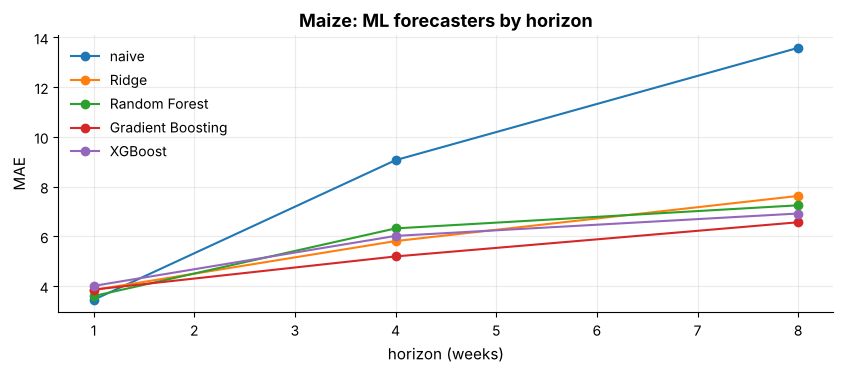

In [8]:
mae_h = pd.DataFrame({n: scores_by_horizon(w)["MAE"] for n, w in wf.items()}).rename_axis("horizon (weeks)")
print("MAE by horizon (lower is better)")
display(mae_h.round(2))
print("\nSkill vs naive (1 - MAE_model / MAE_naive); negative = worse than naive")
display((1 - mae_h.div(mae_h["naive"], axis=0)).drop(columns="naive").round(2))
mae_h.plot(marker="o", figsize=(10, 3.6), title="Maize: ML forecasters by horizon"); plt.ylabel("MAE"); plt.show()

### 🧠 Reading the results
- **h = 1:** naive is essentially unbeatable: most of next week's price *is* this week's price, and the rest is noise. Every ML model is slightly *worse* (negative skill): extra flexibility only adds estimation noise.
- **h = 4:** the ML models cut the naive error by roughly a third to a half; **h = 8:** by roughly 45–50 %. They exploit seasonality and lagged drivers, which matter more the further ahead we look. The gap *widens* with the horizon.
- The ranking among the ML models is close. Gradient boosting leads here, **but in the single split of §3a the random forest led**: the ranking flipped! With only 19 origins, differences of this size are within noise. **Don't crown a winner on thin evidence.**

## 5 · What did the model learn? Permutation importance

*Feature importance* answers "which inputs does the model rely on?". **Permutation importance** shuffles one feature at a time **on a validation set** and measures how much the error worsens: an honest, model-agnostic measure.

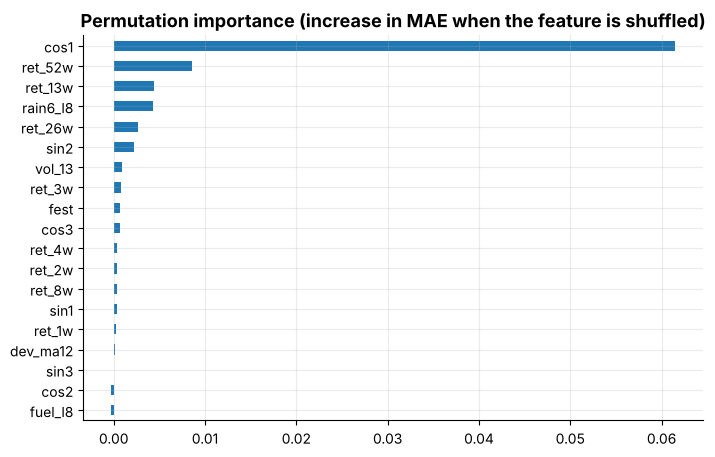

In [9]:
from sklearn.inspection import permutation_importance
xgb = factories["XGBoost"]().fit(Xtr, ytr)                           # trained on the first 80 % (h = 8)
pi = permutation_importance(xgb, Xte, yte, n_repeats=10, random_state=0, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values()
imp.plot.barh(figsize=(8, 5), title="Permutation importance (increase in MAE when the feature is shuffled)"); plt.show()

Expect the **seasonal Fourier terms** and the **lagged drivers** (`rain6_l8`, `fuel_l8`) near the top: exactly the structure we planted in the simulation. A feature with ≈ 0 (or negative) importance is not helping.
> ⚠️ Importance describes *this model on this data*; it is correlation, not proof of causation.

## 6 · Hyper-parameters & time-aware cross-validation

Never tune with shuffled K-fold. Use `TimeSeriesSplit` (expanding window, always validating on the future) and set `gap = h − 1`:

In [10]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
h = 8
X, y = make_ml_table(mz, h=h)
d = X.join(y.rename("y")).dropna()
tr, te = d.iloc[:-52], d.iloc[-52:]                                    # keep the final year untouched

grid = GridSearchCV(XGBRegressor(n_estimators=200, subsample=0.8, random_state=0, n_jobs=1),
                    {"max_depth": [2, 3, 4], "learning_rate": [0.03, 0.1]},
                    cv=TimeSeriesSplit(n_splits=4, gap=h - 1), scoring="neg_mean_absolute_error")
grid.fit(tr.drop(columns="y"), tr["y"])
print("Best hyper-parameters:", grid.best_params_)
print("CV MAE on returns    :", round(-grid.best_score_, 4))

bp = mz["price"].shift(h).loc[te.index]
pred = bp * np.exp(grid.best_estimator_.predict(te.drop(columns="y")))
print(f"Final-year hold-out price MAE: tuned XGB = {mae(mz['price'].loc[te.index], pred):.2f}   |   naive = {mae(mz['price'].loc[te.index], bp):.2f}")

Best hyper-parameters: {'learning_rate': 0.03, 'max_depth': 2}
CV MAE on returns    : 0.0625
Final-year hold-out price MAE: tuned XGB = 6.49   |   naive = 13.62


> 🏛️ **The three-set discipline:** *train* (fit) → *validation* (tune, via `TimeSeriesSplit`) → *test* (the untouched final year, used **once**). If you keep peeking at the test score while tweaking, it silently becomes a validation set and your final number is optimistic.

## 7 · Practical advice

1. **Always start with Ridge + a handful of features**: if XGBoost can't beat it, your features are the problem, not the algorithm.
2. **Target = return (or difference)**, features = scale-free. Rebuild the price from the known base.
3. **Direct strategy** for a few fixed horizons; recursive only when you can forecast every input.
4. **Calendar + lagged drivers** carry the signal on long horizons; *momentum* matters at short ones.
5. **Keep exogenous inputs honest**: lag ≥ horizon. (`arrivals_tonnes` would make any model look brilliant, and be useless.)
6. **Report a baseline-relative skill** and the uncertainty of that skill (number of origins!).
7. **Retrain periodically** in production: markets drift.

## 🧩 Practice problems

### 🧩 Problem 6.1 · Build and inspect a supervised table  ·  🟢 Easy

For **tomato**, build the 1-step-ahead ML table with `make_ml_table(tomato, h=1)`. (a) How many **complete rows** (no NaN in any feature or the target) does it have? Store it in `n_rows`.
  (b) List the feature names. (c) Which feature uses the *oldest* data, and why do the first rows have to be dropped?

<details><summary>💡 Hint 1</summary>

`X, y = make_ml_table(tomato, h=1)`; complete rows: `(X.notna().all(axis=1) & y.notna()).sum()`.

</details>

<details><summary>💡 Hint 2</summary>

`list(X.columns)` shows the names. `ret_52w` is the return over the previous 52 weeks.

</details>

<details><summary>💡 Hint 3</summary>

A 52-week return needs a price 53 weeks back (52 + the h=1 shift), so the first 53 rows can't have it.

</details>

In [11]:
tomato = load_weekly('tomato')
n_rows = None
# YOUR CODE HERE
check('complete rows', n_rows, 573)

⏳ complete rows: not answered yet (replace the `None` with your answer)


### 🧩 Problem 6.2 · Trees can't extrapolate: prove it on rice  ·  🟡 Medium

Rice trends upward strongly. Predict the 8-week-ahead price with a `RandomForestRegressor(200, random_state=0)` in two ways, using the **first 80 %** of rows for training and the **last 20 %** for testing:
  (A) **level target**: features from `make_features(rice, lags=(8, 9, 10, 12, 52), windows=(4, 12), h=8)`, target = price;
  (B) **return target**: `make_ml_table(rice, h=8)`, forecast = `price_{t-8} × exp(predicted return)`.
  Compare MAE and plot actual vs both predictions. Explain the result.

<details><summary>💡 Hint 1</summary>

Chronological split by position: `k = int(len(d) * 0.8)`; train on `[:k]`, test on `[k:]` (after dropping NaN rows).

</details>

<details><summary>💡 Hint 2</summary>

For (B): `base_price = rice['price'].shift(8)` aligned on the table index; forecast = `base_price * np.exp(pred)`.

</details>

<details><summary>💡 Hint 3</summary>

Look at the maximum of the level predictions vs the maximum training target.

</details>

In [12]:
from sklearn.ensemble import RandomForestRegressor
rice = load_weekly('rice')
# YOUR CODE HERE

### 🧩 Problem 6.3 · Ridge vs naive on onion across horizons  ·  🟡 Medium

Using `walk_forward_ml` with a `Ridge` pipeline (`StandardScaler` → `Ridge(alpha=10)`), evaluate **onion** at horizons `(1, 4, 8)` with `initial=470, step=8`.
  Compare against a *zero-return* model (the naive forecast) via MAE by horizon. At which horizons does the ML model beat naive, and by how much (skill = 1 − MAE_model/MAE_naive)?

<details><summary>💡 Hint 1</summary>

`walk_forward_ml(onion, lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)), horizons=(1, 4, 8))`.

</details>

<details><summary>💡 Hint 2</summary>

A naive forecast is a model that always predicts a return of 0. Write a tiny class with `fit` (returns self) and `predict` (returns zeros).

</details>

<details><summary>💡 Hint 3</summary>

`scores_by_horizon(wf)['MAE']` gives MAE per horizon.

</details>

In [13]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
onion = load_weekly('onion')
# YOUR CODE HERE

### 🧩 Problem 6.4 · Time-aware tuning of XGBoost  ·  🟡 Medium

On **maize** (h = 4), tune `XGBRegressor` over `max_depth ∈ {2, 3, 4}` × `learning_rate ∈ {0.03, 0.1}` (use `n_estimators=200`, `subsample=0.8`) with
  `GridSearchCV` and `TimeSeriesSplit(n_splits=4, gap=3)` using `scoring='neg_mean_absolute_error'`, on the training rows *before* the final 52 weeks.
  Then evaluate the best and a default `XGBRegressor(random_state=0)` on the final 52-week hold-out (MAE of the **price** forecast).

<details><summary>💡 Hint 1</summary>

`gap = h - 1 = 3` leaves a buffer so a training target doesn't overlap the validation period.

</details>

<details><summary>💡 Hint 2</summary>

`GridSearchCV(XGBRegressor(...), param_grid, cv=TimeSeriesSplit(n_splits=4, gap=3), scoring='neg_mean_absolute_error')`; then `.fit(Xtr, ytr)`; `best_params_`.

</details>

<details><summary>💡 Hint 3</summary>

Convert predictions back to price: `price.shift(4) * np.exp(pred)` on the test rows.

</details>

In [14]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
mz = load_weekly('maize')
# YOUR CODE HERE

### 🧩 Problem 6.5 · Recursive vs direct for an 8-step forecast  ·  🔴 Challenge

On **maize** use only the **last 4 weekly log returns** as features. Train on the first 470 weeks, then evaluate at *every* origin in the remaining weeks (no refitting):
  (A) **Direct**: a `Ridge(alpha=1)` mapping the 4 returns at the origin to the 8-week log return.
  (B) **Recursive**: a `Ridge(alpha=1)` mapping 4 returns to the *next-week* return; apply it 8 times, feeding each prediction back in.
  Report the MAE of the 8-week-ahead price forecast for both and for naive.

<details><summary>💡 Hint 1</summary>

Weekly log returns: `r = np.log(price).diff()`; features at origin t: `[r[t], r[t-1], r[t-2], r[t-3]]`: build them with `np.column_stack([r.shift(k) for k in range(4)])`.

</details>

<details><summary>💡 Hint 2</summary>

Direct target: `np.log(price).shift(-8) - np.log(price)`. Recursive target: `r.shift(-1)`.

</details>

<details><summary>💡 Hint 3</summary>

Recursive loop: `window = [r_t, r_{t-1}, r_{t-2}, r_{t-3}]`; repeat 8 times: `pred = model.predict([window])`; `total += pred`; `window = [pred] + window[:3]`.

</details>

In [15]:
from sklearn.linear_model import Ridge
mz = load_weekly('maize')
lp = np.log(mz['price']); r = lp.diff()
# YOUR CODE HERE

## ✅ Recap
- ML forecasting = **feature engineering** (lags, rolling stats, calendar, lagged drivers) + a regressor.
- **Trees cannot extrapolate** → model *returns*, rebuild the price from the latest known value.
- **Direct** multi-step: one model per horizon. Evaluate with **walk-forward**, tune with **`TimeSeriesSplit` (+ gap)**.
- Boosting (GBM/XGBoost) is usually strongest, but a regularised linear model is the right first baseline.
- **Permutation importance** shows what the model uses; seasonality and lagged drivers dominate for long horizons.

### ⚠️ Common mistakes
1. Predicting raw price levels with tree models on a trending series.
2. Random-shuffle cross-validation (use `TimeSeriesSplit`).
3. Scaling with statistics computed on the whole dataset (keep scalers *inside* the pipeline / fit on train only).
4. Using same-week exogenous values (arrivals, today's rain) as predictors.
5. Tuning against the final test set.

### 🔮 Next lesson
Can a neural network read the *raw sequence* and learn its own features? **Lesson 7** introduces RNNs, LSTMs, GRUs and Transformers for forecasting, and we will hold them to the same walk-forward standard.